## Actor-Critic – Stage 3 최종 모델 (Seed 42)
**실험 조건:**

메뉴 종류: 4개 (치즈, 페퍼로니, 머쉬룸, 스페셜)

재료 종류: 5개 (도우, 치즈, 페퍼로니, 머쉬룸, 올리브)

최대 주문 대기 수: 4개

행동 종류: 7개

주문 타이머: 36~48스텝

주문 처리 방식: 전체 메뉴 기준 FIFO

정답 서빙 보상: +150

타임아웃 페널티: -50

잘못된 서빙 페널티: -15

잘못된 재료 조작 페널티: -2

행동당 페널티: -0.1

신경망 구조: 공유 은닉층(256개 뉴런), Actor/Critic 출력층 분리

학습 방식: 1-step TD, 최대 10스텝 단위 업데이트

학습 에피소드: 4,000

할인율(γ): 0.98

학습률(Learning Rate): 0.0002

Optimizer: Adam

학습 시 보상 스케일링: ÷100

Reward Shaping: 올바른 순서의 필요 재료 추가 시 +5, 마지막 필요 재료 추가로 피자 완성 시 +10

엔트로피 보너스 계수: 0.05

학습 시드(Seed): 42

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -261.18 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -267.54 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -245.78 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -228.34 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -223.25 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -187.32 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -188.67 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -155.12 | Success: 1 | Timeout: 3
Episode  450 | Avg Reward (50):  -140.83 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -158.86 | Success: 1 | Timeout: 3
Checkpoint saved: episode 500 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -109.60 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):   -63

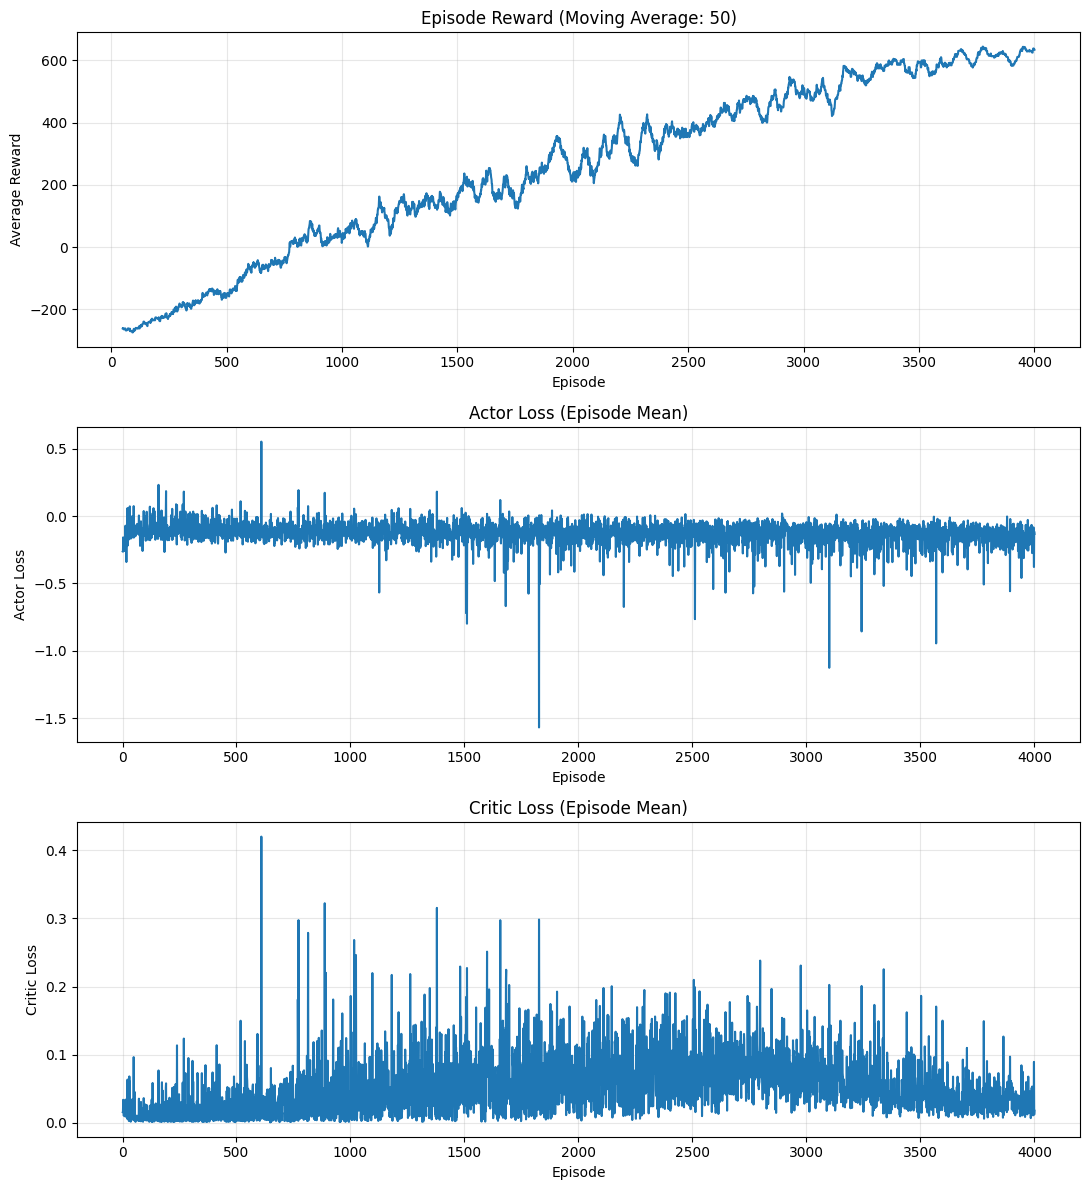

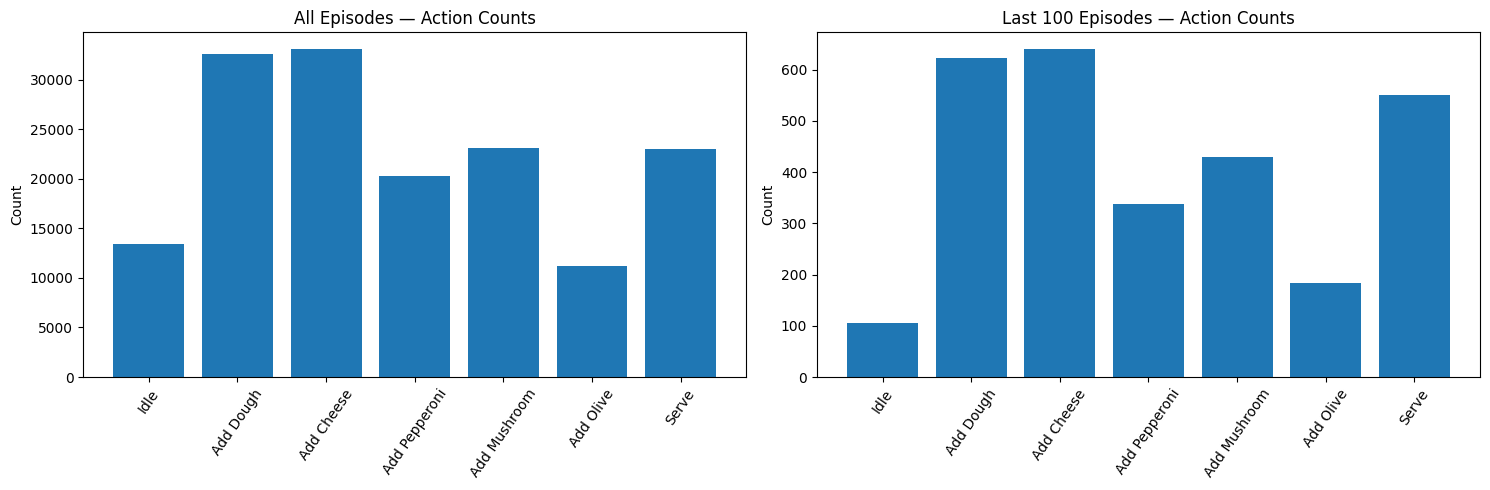

=== Last 100 Episodes Action Distribution ===
Idle            :   3.69%
Add Dough       :  21.69%
Add Cheese      :  22.32%
Add Pepperoni   :  11.73%
Add Mushroom    :  14.97%
Add Olive       :   6.41%
Serve           :  19.19%


In [1]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 4000 # ⭐ 학습 에피소드 2000 → 4000으로 증가
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp6_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp6_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 6-1 (Seed 42, Entropy 0.05, 4000 Episodes, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

세부 실험 과정 및 결과 분석은 03_1_actor_critic.ipynb 참고.